## Notebook setup

This notebook follows the [data preparation notebook](https://github.com/ycma-data/DSC-680-Capstone/blob/main/notebooks/01_data_preparation.ipynb).

In [1]:
## Notebook setup & library loading

# Pandas is the main way to work with the dataframes
import os
import pandas as pd
# removes the scientific notation that can be used in outputs with Pandas
pd.set_option('display.float_format', '{:,.2f}'.format)
# pandas defaults to not showing all rows. The template shows all rows (None);
# here the limit is 100 because the institution table has more than 1,600 rows
pd.set_option('display.max_rows', 100)
# pandas defaults to not showing all columns, this option ensures all columns are shown
pd.set_option('display.max_columns', None)

# MatPlotLib is a common visualization package (used for the plots in this notebook)
from matplotlib import pyplot as plt
# renders the figures in the notebook
%matplotlib inline

# numpy is the fundamental package for scientific computing with Python
import numpy as np
# To make outputs more understandable, remove the scientific notation
np.set_printoptions(suppress=True)

# Random seed
SEED = 42
np.random.seed(SEED)

print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 2.2.3 | numpy 2.4.6


In [2]:
# Packages & Libraries needed to load data from Google Drive
# TIP: Load data just once.
# https://pypi.org/project/PyDrive2/

!pip install -U -q PyDrive2
from pydrive2.auth import GoogleAuth
from pydrive2.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
joserfc 1.8.0 requires cryptography>=45.0.1, but you have cryptography 43.0.3 which is incompatible.
authlib 1.9.3 requires cryptography>=45.0.1, but you have cryptography 43.0.3 which is incompatible.


In [4]:
# Data loading: the analysis file made by notebook 01 (one row per institution), stored in the GitHub repository
url = 'https://raw.githubusercontent.com/ycma-data/DSC-680-Capstone/main/data/institutions.csv'
df = pd.read_csv(url)
print("institutions.csv Data Shape: ", df.shape)
display(df[['INSTNM', 'sector', 'T2018', 'label_5', 'label_10', 'exit_final']].head())

institutions.csv Data Shape:  (1608, 54)


,INSTNM,sector,T2018,label_5,label_10,exit_final
0,Alabama A & M University,public,"4,990.00",resilient,resilient,False
1,Faulkner University,private nonprofit,"2,079.00",vulnerable,vulnerable,False
2,University of Montevallo,public,"2,251.00",recovered,resilient,False
3,Alabama State University,public,"3,903.00",vulnerable,vulnerable,False
4,Athens State University,public,"2,732.00",vulnerable,vulnerable,False


In [5]:
# Folder for the figures (PNG files) and a small function that saves the current figure
FIG_DIR = '/content/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=200, bbox_inches='tight')

## Step 1. Sample by sector, size, region and locale

The sample started with 6,807 campus records in the College Scorecard 2018-19 file. Notebook 01 kept four-year, bachelor's predominant, public and private nonprofit campuses. It dropped online-only campuses, service schools, outlying areas, and campuses with fewer than 100 undergraduates. That left 1,701 campus records. After combining campuses with the same OPEID6, the samples had 1,608 institutions.

Note: Label_5 and label_10 are the three enrollment labels (resilient, recovered, vulnerable) at the 5% and 10% tolerance. The 10% tolerance is the main label (see step 4), and 5% label is a sensitivity check.

In [6]:
# size bands from Fall 2018 undergraduate enrollment
bins = [0, 1000, 3000, 10000, float('inf')]
band_names = ['under 1,000', '1,000 to 2,999', '3,000 to 9,999', '10,000 or more']
df['size_band'] = pd.cut(df['T2018'], bins=bins, labels=band_names, right=False)

# readable names for the codes (REGION: BEA regions; LOCALE: city, suburb, town, rural)
region_names = {1: 'New England', 2: 'Mid East', 3: 'Great Lakes', 4: 'Plains', 5: 'Southeast',
                6: 'Southwest', 7: 'Rocky Mountains', 8: 'Far West'}
df['region'] = df['REGION'].map(region_names)
locale_groups = {11: 'city', 12: 'city', 13: 'city', 21: 'suburb', 22: 'suburb', 23: 'suburb',
                 31: 'town', 32: 'town', 33: 'town', 41: 'rural', 42: 'rural', 43: 'rural'}
df['locale_group'] = df['LOCALE'].map(locale_groups)

# four outcome groups: exit colleges are separated from the other vulnerable colleges
df['group4'] = np.where(df['exit_final'], 'exit', df['label_10'])
df['group4'] = df['group4'].replace({'vulnerable': 'vulnerable (open)'})

label_order = ['resilient', 'recovered', 'vulnerable']
group_order = ['resilient', 'recovered', 'vulnerable (open)', 'exit']
colors = {'resilient': '#4C9F70', 'recovered': '#E0B341', 'vulnerable': '#C8553D',
          'vulnerable (open)': '#C8553D', 'exit': '#6B2D5C'}

print(df['sector'].value_counts().to_string())
print()
print(pd.crosstab(df['size_band'], df['sector'], margins=True).to_string())
print()
print(pd.crosstab(df['region'], df['sector'], margins=True).to_string())
print()
print(pd.crosstab(df['locale_group'], df['sector'], margins=True).to_string())

sector
private nonprofit    1082
public                526

sector          private nonprofit  public   All
size_band                                      
under 1,000                   395      23   418
1,000 to 2,999                487      91   578
3,000 to 9,999                176     207   383
10,000 or more                 24     205   229
All                          1082     526  1608

sector           private nonprofit  public   All
region                                          
Far West                       109      54   163
Great Lakes                    186      67   253
Mid East                       232      80   312
New England                    106      35   141
Plains                         120      54   174
Rocky Mountains                 17      26    43
Southeast                      252     147   399
Southwest                       60      63   123
All                           1082     526  1608

sector        private nonprofit  public   All
locale_group     

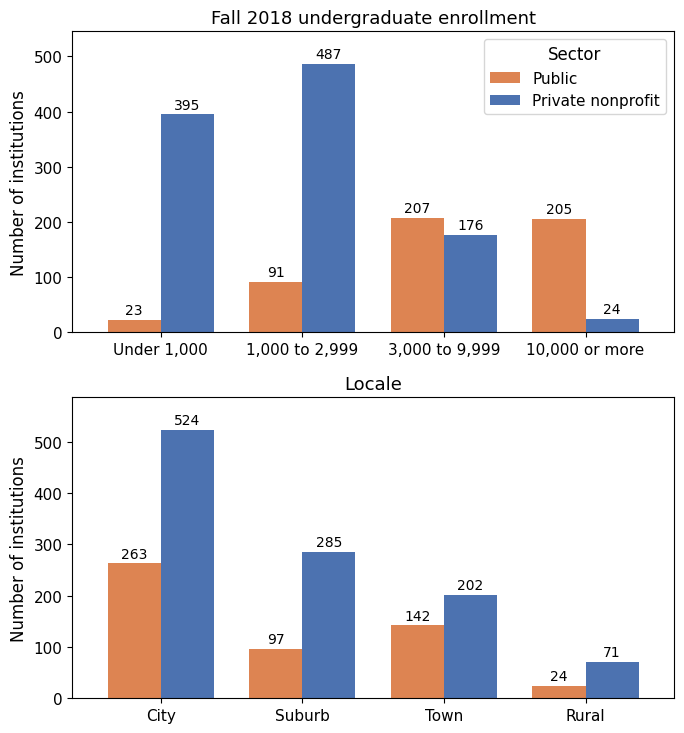

In [7]:
# Visualization: sample composition by sector, for size band, and locale
locale_order = ['city', 'suburb', 'town', 'rural']
panels = [('size_band', band_names, 'Fall 2018 undergraduate enrollment'),
          ('locale_group', locale_order, 'Locale')]

with plt.rc_context({'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12,
                     'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11}):
    fig, axes = plt.subplots(2, 1, figsize=(7, 7.5))
    for ax, (col, order, title) in zip(axes, panels):
        counts = pd.crosstab(df[col], df['sector']).reindex(order)[['public', 'private nonprofit']]
        counts.index = [s[0].upper() + s[1:] for s in counts.index]
        counts.columns = ['Public', 'Private nonprofit']
        counts.plot(kind='bar', ax=ax, color=['#DD8452', '#4C72B0'], rot=0, width=0.75, legend=False)
        for container in ax.containers:
            ax.bar_label(container, fontsize=10, padding=2)   # count on top of each bar
        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylabel('Number of institutions')
        ax.margins(y=0.12)                                     # room for the bar labels
    axes[0].legend(title='Sector')
    fig.tight_layout()
    save_fig('fig00_sample_composition')
    plt.show()

The sample had 526 public and 1,082 private nonprofit institutions. The two sectors differed in size. Most private nonprofit colleges were small, while most public colleges were large. The Southeast and the Mid East had the most colleges. The Rocky Mountains had the fewest. About half of the institutions were in cities. Rural were the smallest group. The smallest groups were private nonprofit colleges in the Rocky Mountains (17), public colleges with fewer than 1,000 undergraduates (23), public rural colleges (24), and private nonprofit colleges with 10,000 or more undergraduates (24).

## Step 2. Class sizes at 5% and 10%

The outcome has three classes. This step shows how many institutions are in each class at the 5% and 10% tolerance, by sector. A class that is much smaller than the others needs class weights and per-class metrics in the models.

In [ ]:
# Counts and percentages by sector, at 5% and 10%
for col, title in [('label_5', '5% tolerance'), ('label_10', '10% tolerance')]:
    counts = pd.crosstab(df['sector'], df[col])[label_order]
    counts.loc['all'] = counts.sum()
    pct = counts.div(counts.sum(axis=1), axis=0) * 100
    both = counts.astype(str) + ' (' + pct.round(1).astype(str) + '%)'
    print(f'Count and percent of institutions ({title})')
    print(both.to_string())
    print()

Count and percent of institutions (5% tolerance)
label_5              resilient    recovered   vulnerable
sector                                                  
private nonprofit  298 (27.5%)  174 (16.1%)  610 (56.4%)
public             152 (28.9%)   61 (11.6%)  313 (59.5%)
all                450 (28.0%)  235 (14.6%)  923 (57.4%)

Count and percent of institutions (10% tolerance)
label_10             resilient    recovered   vulnerable
sector                                                  
private nonprofit  419 (38.7%)  135 (12.5%)  528 (48.8%)
public             225 (42.8%)    45 (8.6%)  256 (48.7%)
all                644 (40.0%)  180 (11.2%)  784 (48.8%)



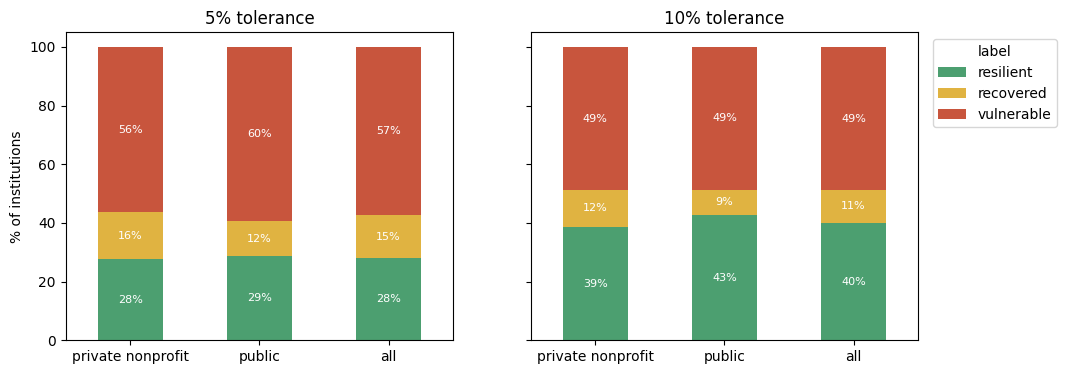

In [ ]:
# Visualization: stacked bars, 5% and 10% side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (col, title) in zip(axes, [('label_5', '5% tolerance'), ('label_10', '10% tolerance')]):
    counts = pd.crosstab(df['sector'], df[col])[label_order]
    counts.loc['all'] = counts.sum()
    pct = counts.div(counts.sum(axis=1), axis=0) * 100
    pct.plot(kind='bar', stacked=True, ax=ax, color=[colors[c] for c in label_order], legend=False, rot=0)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f%%', label_type='center', fontsize=8, color='white')
    ax.set_title(title)
    ax.set_xlabel('')
axes[0].set_ylabel('% of institutions')
axes[1].legend(title='label', bbox_to_anchor=(1.02, 1), loc='upper left')
save_fig('fig01_class_balance')
plt.show()

The output showed that at the 5% tolerance, the classes are 28.0% resilient, 14.6% recovered, and 57.4% vulnerable. While at the 10% tolerance, the recovered falls to 11.2% (8.6% for public colleges). Recovered was the smallest class in both sectors. Without class weights, a model can do well by favoring the largest class. As a result, the analysis applied class weights to all three-class models and reported per-class precision and recall.

In [ ]:
# How large were the losses behind the "vulnerable" label? (fall 2024 compared with fall 2018)
exited = df['exit_final'].astype(bool)
index24 = df['T2024'] / df['T2018']
vul10 = df['label_10'] == 'vulnerable'

# 1. Share labeled vulnerable if the required loss were larger (exits count as vulnerable at every threshold)
rows = []
for tol in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    vul = (index24 < 1 - tol) | exited
    rows.append({'required loss': f'more than {tol:.0%}',
                 'all (%)': vul.mean() * 100,
                 'public (%)': vul[df['sector'] == 'public'].mean() * 100,
                 'private nonprofit (%)': vul[df['sector'] == 'private nonprofit'].mean() * 100})
print(pd.DataFrame(rows).round(1).to_string(index=False))
print()

# 2. Open vulnerable institutions: how far below the 0.90 line were they in fall 2024?
open_vul = vul10 & ~exited
idx = index24[open_vul]
print('Vulnerable institutions:', int(vul10.sum()), '| stayed open:', int(open_vul.sum()), '| exited:', int(exited.sum()))
print('Median fall 2024 index, open vulnerable institutions:', round(idx.median(), 3))
print('Share that lost 10% to 15% (index 0.85 to 0.90):', round(((idx >= 0.85) & (idx < 0.90)).mean() * 100, 1))
print('Share that lost more than 20% (index below 0.80):', round((idx < 0.80).mean() * 100, 1))
print('Open institutions that lost more than 20%:', int((index24[~exited] < 0.80).sum()), 'of', int((~exited).sum()))
print()

# 3. Institutions vs. students
total18, total24 = df['T2018'].sum(), df['T2024'].fillna(0).sum()
print('Share of institutions labeled vulnerable (%):', round(vul10.mean() * 100, 1))
print('Share of fall 2018 undergraduates at vulnerable institutions (%):',
      round(df.loc[vul10, 'T2018'].sum() / total18 * 100, 1))
print('Change in total undergraduate enrollment, fall 2018 to fall 2024 (%):', round((total24 / total18 - 1) * 100, 1))

required loss  all (%)  public (%)  private nonprofit (%)
 more than 5%    57.40       59.50                  56.40
more than 10%    48.80       48.70                  48.80
more than 15%    39.80       39.00                  40.20
more than 20%    31.30       27.60                  33.10
more than 25%    23.10       18.30                  25.50
more than 30%    17.40       11.80                  20.10

Vulnerable institutions: 784 | stayed open: 711 | exited: 73
Median fall 2024 index, open vulnerable institutions: 0.772
Share that lost 10% to 15% (index 0.85 to 0.90): 20.3
Share that lost more than 20% (index below 0.80): 60.5
Open institutions that lost more than 20%: 430 of 1535

Share of institutions labeled vulnerable (%): 48.8
Share of fall 2018 undergraduates at vulnerable institutions (%): 33.9
Change in total undergraduate enrollment, fall 2018 to fall 2024 (%): -3.0


## Step 3. Exit events (closures and mergers)

In [ ]:
exits = df[df['exit_final']].copy()
print(pd.crosstab(exits['sector'], exits['exit_event_type'], margins=True).to_string())
print()

exit_event_type    closure  merger  All
sector                                 
private nonprofit       48      15   63
public                   0      10   10
All                     48      25   73



exit_event_type  closure  merger
exit_year                       
2017                   0       1
2018                   0       0
2019                   8       3
2020                   6       7
2021                   5       1
2022                   2       9
2023                  11       4
2024                  16       0


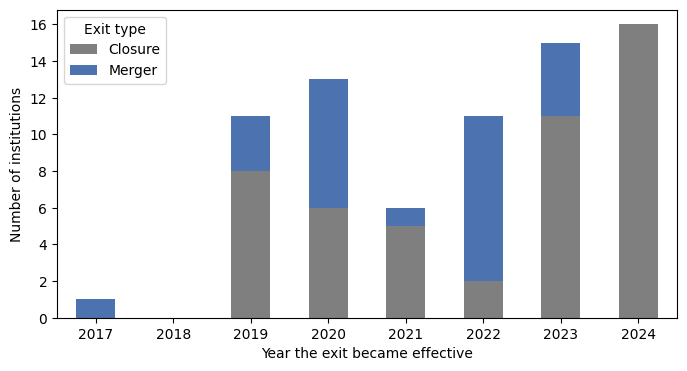

In [ ]:
# exit events by effective year and type
exits['exit_year'] = exits['exit_effective_year'].astype(int)
by_year = pd.crosstab(exits['exit_year'], exits['exit_event_type'])
by_year = by_year.reindex(range(by_year.index.min(), by_year.index.max() + 1), fill_value=0)  # include years with no exits, such as 2018
print(by_year.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
by_year.plot(kind='bar', stacked=True, ax=ax, color=['#7F7F7F', '#4C72B0'], rot=0)
ax.set_xlabel('Year the exit became effective')
ax.set_ylabel('Number of institutions')
ax.legend(['Closure', 'Merger'], title='Exit type')
save_fig('fig02_exit_events_by_year')
plt.show()

In [ ]:
# share of private nonprofit colleges that exited, by size band
pn = df[df['sector'] == 'private nonprofit']
share = pd.crosstab(pn['size_band'], pn['exit_final'], normalize='index') * 100
counts = pd.crosstab(pn['size_band'], pn['exit_final'])
size_table = pd.DataFrame({'exits': counts[True], 'institutions': counts.sum(axis=1), 'exit %': share[True].round(1)})
print()
print('Private nonprofit institutions that exited, by size band:')
print(size_table.to_string())


Private nonprofit institutions that exited, by size band:
                exits  institutions  exit %
size_band                                  
under 1,000        46           395   11.60
1,000 to 2,999     16           487    3.30
3,000 to 9,999      0           176    0.00
10,000 or more      1            24    4.20


In [ ]:
# overall exit rate and median Fall 2018 enrollment (private nonprofit)
print()
print('Overall private nonprofit exit rate (%):', round(pn['exit_final'].mean() * 100, 1),
      f"({int(pn['exit_final'].sum())} of {len(pn)})")
print('Median Fall 2018 enrollment, exit:', pn.loc[pn['exit_final'], 'T2018'].median(),
      '| not exit:', pn.loc[~pn['exit_final'], 'T2018'].median())


Overall private nonprofit exit rate (%): 5.8 (63 of 1082)
Median Fall 2018 enrollment, exit: 531.0 | not exit: 1453.0


The sample had 73 verified exits: 48 closures and 25 mergers. Private nonprofit colleges had 63 exits (48 closures and 15 mergers), and public colleges had 10 (all mergers).

Apart from one merger with a legal effective date of 2017, exits took effect in every year from 2019 to 2024, and none took effect in 2018. Mergers peaked in 2022 (9). All six belong to Pennsylvania’s State System of Higher Education (PASSHE). The consolidation created two new universities in 2022. Bloomsburg, Lock Haven, and Mansfield became Commonwealth University of Pennsylvania. California, Clarion, and Edinboro became Pennsylvania Western University (PennWest).

Small private nonprofit colleges exited far more often. Among those with fewer than 1,000 undergraduates, 11.6% exited. The overall private nonprofit exit rate was 5.8%. The median Fall 2018 enrollment of private nonprofit exit colleges was 531.

## Step 4. Noise check for the 5% threshold

Between Fall 2018 and Fall 2019, before the pandemic, how much does enrollment normally move? If many colleges change by more than 5% in a normal year, a 5% band is narrow. This is the evidence for choosing between the 5% and 10% thresholds.

In [ ]:
open_df = df[~df['exit_final']].copy()          # colleges that did not exit
change = (open_df['T2019'] / open_df['T2018'] - 1).dropna()

print('Institutions:', len(change))
print('Median change (%):', round(change.median() * 100, 1))
print('Middle half (25th to 75th percentile, %):', (change.quantile([0.25, 0.75]) * 100).round(1).tolist())
print('Changed by 5% or less in either direction (%):', round((change.abs() <= 0.05).mean() * 100, 1))
print('Changed by 10% or less in either direction (%):', round((change.abs() <= 0.10).mean() * 100, 1))
print('Fell by more than 5% (%):', round((change < -0.05).mean() * 100, 1))
print('Fell by more than 10% (%):', round((change < -0.10).mean() * 100, 1))

Institutions: 1535
Median change (%): -1.4
Middle half (25th to 75th percentile, %): [-4.9, 1.4]
Changed by 5% or less in either direction (%): 65.7
Changed by 10% or less in either direction (%): 88.5
Fell by more than 5% (%): 24.8
Fell by more than 10% (%): 7.1


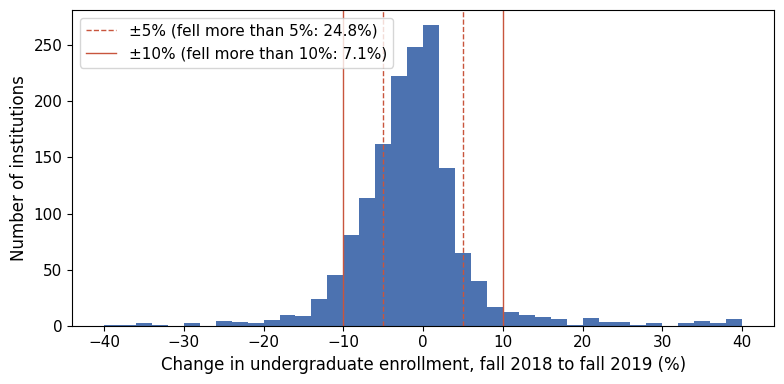

In [ ]:
fell5 = (change < -0.05).mean() * 100
fell10 = (change < -0.10).mean() * 100

with plt.rc_context({'font.size': 12, 'axes.labelsize': 12, 'xtick.labelsize': 11,
                     'ytick.labelsize': 11, 'legend.fontsize': 11}):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(change.clip(-0.4, 0.4) * 100, bins=40, color='#4C72B0')      # values beyond ±40% are shown at the edge
    for x in [-5, 5]:
        ax.axvline(x, color='#C8553D', linestyle='--', linewidth=1,
                   label=f'±5% (fell more than 5%: {fell5:.1f}%)' if x == -5 else None)
    for x in [-10, 10]:
        ax.axvline(x, color='#C8553D', linestyle='-', linewidth=1,
                   label=f'±10% (fell more than 10%: {fell10:.1f}%)' if x == -10 else None)
    ax.set_xlabel('Change in undergraduate enrollment, fall 2018 to fall 2019 (%)')
    ax.set_ylabel('Number of institutions')
    ax.legend(loc='upper left')
    fig.tight_layout()
    save_fig('fig03_noise_2018_2019')
    plt.show()

From Fall 2018 to Fall 2019, the median change in enrollment was −1.4%. The middle half of colleges changed by between −4.9% and +1.4%. About two-thirds (65.7%) changed by 5% or less in either direction, and 88.5% changed by 10% or less.

In this normal year, 24.8% of colleges fell by more than 5%, but only 7.1% fell by more than 10%. A 5% band therefore labeled many colleges as declining because of ordinary year-to-year movement.

**Decision**: The outcome supported the 10% tolerance as the main threshold. The main model will rerun with 5% labels as a sensitivity check.

## Step 5. Median enrollment paths by label and sector

The enrollment index is an institutioin's enrollment in a given year divided by its Fall 2018 enrollment. The median enrollment index shows the typical path of that group without the pull of a few extreme colleges.

The paths used the 1,535 colleges that did not exit, so the vulnerable group here is vulnerable (open). Closed and merged colleges are left out because their enrollment paths are incomplete.

The figure showed what the labels look like, and the timing, shape, and size of the change, which the label rules do not fix.

In [ ]:
# colleges that did not exit, and each college's enrollment index for each year
years = list(range(2018, 2025))
open_df = df[~df['exit_final']].copy()
open_df['idx2018'] = 1.0
for y in range(2019, 2025):
    open_df[f'idx{y}'] = open_df[f'T{y}'] / open_df['T2018']

# table of the median index, by label (exit colleges are not included)
table = open_df.groupby('label_10')[[f'idx{y}' for y in years]].median().round(2)
table = table.rename(index={'vulnerable': 'vulnerable (open)'})
table.insert(0, 'institutions', open_df['label_10'].value_counts().rename(index={'vulnerable': 'vulnerable (open)'}))
print('Median enrollment index by label (10% tolerance), colleges still open in Fall 2024')
print(table.to_string())

# table of the median index, by sector
table_sector = open_df.groupby('sector')[[f'idx{y}' for y in years]].median().round(2)
table_sector.insert(0, 'institutions', open_df['sector'].value_counts())
print()
print('Median enrollment index by sector, colleges still open in Fall 2024')
print(table_sector.to_string())

Median enrollment index by label (10% tolerance), colleges still open in Fall 2024
                   institutions  idx2018  idx2019  idx2020  idx2021  idx2022  idx2023  idx2024
label_10                                                                                      
recovered                   180     1.00     0.97     0.92     0.90     0.89     0.93     0.98
resilient                   644     1.00     1.01     1.02     1.03     1.03     1.04     1.06
vulnerable (open)           711     1.00     0.96     0.91     0.85     0.80     0.78     0.77

Median enrollment index by sector, colleges still open in Fall 2024
                   institutions  idx2018  idx2019  idx2020  idx2021  idx2022  idx2023  idx2024
sector                                                                                        
private nonprofit          1019     1.00     0.99     0.95     0.94     0.91     0.92     0.93
public                      516     1.00     0.99     0.96     0.93     0.90     0.90   

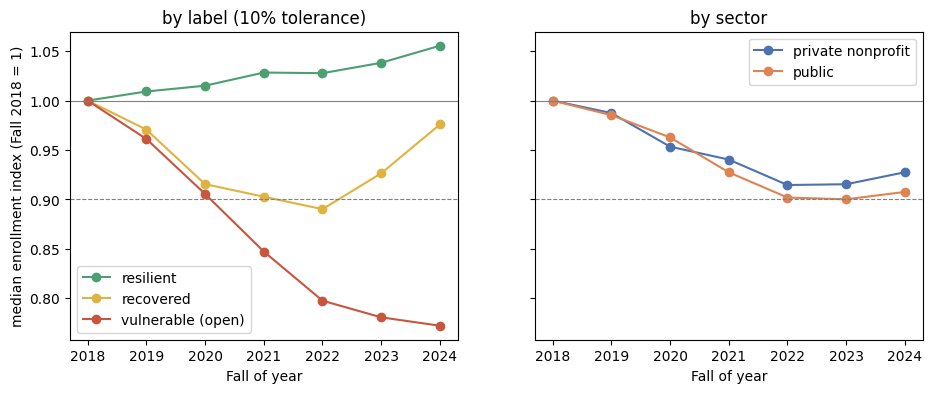

In [ ]:
# Visualization: median enrollment index by label and by sector
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
# left: median index for each label
for lab in label_order:
    med = []
    for y in years:
        med.append(open_df.loc[open_df['label_10'] == lab, f'idx{y}'].median())
    name = 'vulnerable (open)' if lab == 'vulnerable' else lab
    axes[0].plot(years, med, marker='o', label=name, color=colors[lab])
axes[0].set_title('by label (10% tolerance)')
# right: median index for each sector
for sec, col in [('private nonprofit', '#4C72B0'), ('public', '#DD8452')]:
    med = []
    for y in years:
        med.append(open_df.loc[open_df['sector'] == sec, f'idx{y}'].median())
    axes[1].plot(years, med, marker='o', label=sec, color=col)
axes[1].set_title('by sector')
for ax in axes:
    ax.axhline(1.0, color='grey', linewidth=0.8)
    ax.axhline(0.90, color='grey', linewidth=0.8, linestyle='--')     # the 10% tolerance line
    ax.set_xlabel('Fall of year')
    ax.legend()
axes[0].set_ylabel('median enrollment index (Fall 2018 = 1)')
save_fig('fig04_enrollment_paths')
plt.show()

The figure showed that the groups were already apart in Fall 2019, before COVID. The low point came in 2022, and recovery came mostly in 2023 and 2024. Resilient colleges grew to 1.06. The two sectors followed similar paths. Both fell to about 0.90 by Fall 2022 and rose only slightly by Fall 2024.

## Step 6. Pre-2018 trend by outcome group

The pre-2018 trend is the log change in enrollment from Fall 2013 to Fall 2018 (capped at the 1st and 99th percentiles). If colleges that were already shrinking before 2018 did worse afterwards, this could be a possible early warning sign.

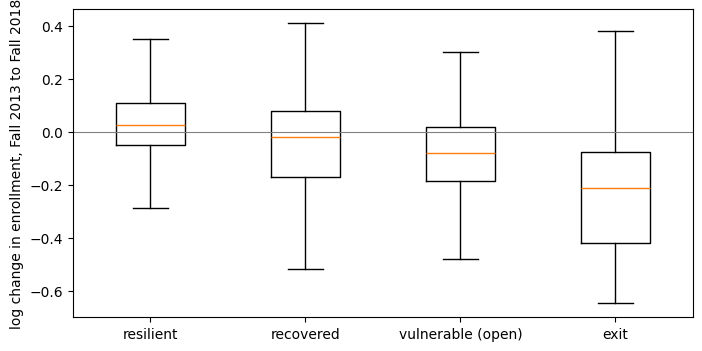

            group  institutions  median change 2013-2018 (%)  share that fell by more than 10% (%)
        resilient           634                         2.80                                 17.00
        recovered           176                        -1.80                                 32.40
vulnerable (open)           711                        -7.60                                 43.20
             exit            72                       -19.10                                 68.10

Institutions that lost more than half of their enrollment between 2013 and 2018: 11
  of these, exited by 2024: 5


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
data = []
for g in group_order:
    data.append(df.loc[df['group4'] == g, 'trend_13_18'].dropna())
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(group_order) + 1))
ax.set_xticklabels(group_order)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_ylabel('log change in enrollment, Fall 2013 to Fall 2018')
save_fig('fig05_pre2018_trend_by_group')
plt.show()

rows = []
for g in group_order:
    t = df.loc[df['group4'] == g, 'trend_13_18'].dropna()
    rows.append({'group': g, 'institutions': len(t),
                 'median change 2013-2018 (%)': round((np.exp(t.median()) - 1) * 100, 1),
                 'share that fell by more than 10% (%)': round((t < np.log(0.90)).mean() * 100, 1)})
print(pd.DataFrame(rows).to_string(index=False))

# institutions that lost more than half of their enrollment between 2013 and 2018
big_drop = df[df['trend_13_18_raw'] < np.log(0.5)]
print()
print('Institutions that lost more than half of their enrollment between 2013 and 2018:', len(big_drop))
print('  of these, exited by 2024:', int(big_drop['exit_final'].sum()))

Colleges that did worse after 2018 were already doing worse before 2018. The median change from Fall 2013 to Fall 2018 was +2.8% for resilient colleges, −1.8% for recovered colleges, −7.6% for vulnerable (open) colleges, and −19.1% for exit colleges. The share that fell by more than 10% over those five years rose in the same order: 17.0%, 32.4%, 43.2%, and 68.1%. Eleven institutions lost more than half of their enrollment between 2013 and 2018, and five of them exited by 2024.

The boxes overlapped, so the trend alone did not separate the groups, but the clear order across the four groups suggested that the pre-2018 trend was a possible early warning sign.

## Step 7. Log of enrollment

Logistic regression assumes each added unit has the same effect. With raw enrollment, 500 extra students would count the same for a small college with 2,000 students as for a univeristy with 20,000 students. But this is not realistic. The log solves this by turning equal ratios into equal steps. The log also limits the pull of a few very large institutions.

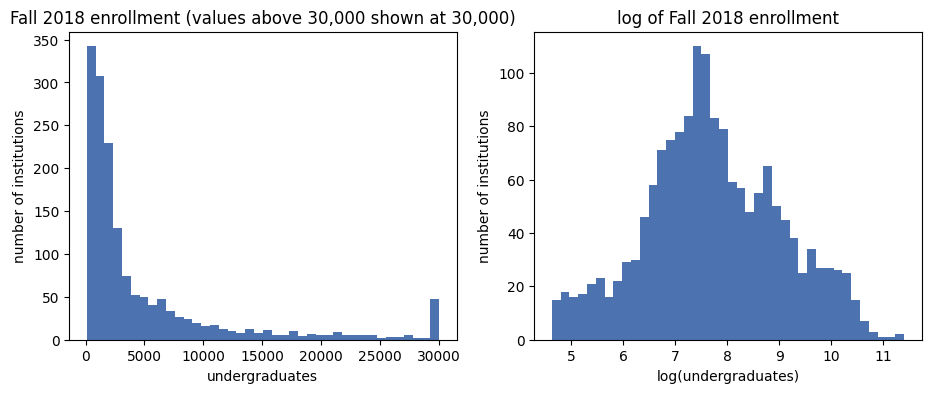

Skewness of enrollment: 3.64 | skewness of the log: 0.05


In [ ]:
# Distribution of Fall 2018 enrollment: raw vs. log
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df['T2018'].clip(upper=30000), bins=40, color='#4C72B0')
axes[0].set_title('Fall 2018 enrollment (values above 30,000 shown at 30,000)')
axes[0].set_xlabel('undergraduates')
axes[1].hist(df['log_enroll'], bins=40, color='#4C72B0')
axes[1].set_title('log of Fall 2018 enrollment')
axes[1].set_xlabel('log(undergraduates)')
for ax in axes:
    ax.set_ylabel('number of institutions')
save_fig('fig06_enrollment_raw_and_log')
plt.show()
print('Skewness of enrollment:', round(df['T2018'].skew(), 2), '| skewness of the log:', round(df['log_enroll'].skew(), 2))

Enrollment was strongly right-skewed (skewness=3.64), with a few very large institutions far from the rest. The log reduced the skew almost completely (skewness=0.05). The logistic regression models used the log of enrollment, so that size had a proportional effect and the largest institutions did not dominate the estimate. The random forest models did not need the log, because their splits depend only on the order of the values.


label_10        resilient  recovered  vulnerable
size_band                                       
under 1,000         33.70      16.70       49.50
1,000 to 2,999      35.30      11.40       53.30
3,000 to 9,999      39.40       8.60       52.00
10,000 or more      64.60       4.80       30.60


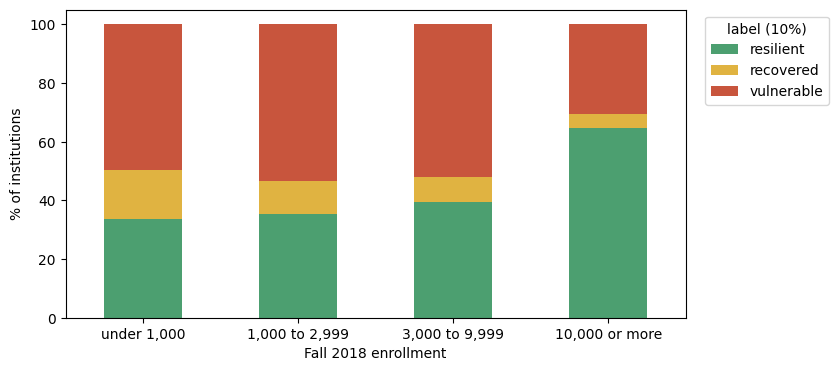

In [ ]:
# label shares by size band
pct = pd.crosstab(df['size_band'], df['label_10'], normalize='index')[label_order] * 100
print()
print(pct.round(1).to_string())
fig, ax = plt.subplots(figsize=(8, 4))
pct.plot(kind='bar', stacked=True, ax=ax, color=[colors[c] for c in label_order], rot=0)
ax.set_xlabel('Fall 2018 enrollment')
ax.set_ylabel('% of institutions')
ax.legend(title='label (10%)', bbox_to_anchor=(1.02, 1), loc='upper left')
save_fig('fig07_labels_by_size_band')
plt.show()

This step asked whether size was related to the outcome. The share of resilient colleges rose with size, from 33.7% for colleges under 1,000 to 64.6% for colleges with 10,000 or more. The share of recovered colleges fell with size, from 16.7% to 4.8%. The vulnerable share was about half in the three smaller bands (49.5% to 53.3%). It dropped to 30.6% only in the largest band, 10,000 or more.

Size therefore mattered mainly at the large end. Because 205 of the 229 largest colleges were public, part of this pattern may reflect sector rather than size.

## Step 8. Missing-data pattern

**What is missing**

This step describes the missing data: the percent missing for each characteristic, by sector, and whether colleges that exited have more missing data (Kelchen et al., 2025, found that colleges that close have unusually high rates of missing data).

                     overall %  public %  private nonprofit %
ADM_RATE                 10.20      9.50                10.50
endow_per_student         4.90      1.90                 6.30
net_price                 3.70      3.60                 3.80
grant_aid_intensity       3.70      3.60                 3.80
C150_4                    3.50      4.40                 3.10
RET_FT4                   3.40      3.60                 3.30
DEBT_MDN                  3.20      0.40                 4.60
MD_EARN_WNE_P7            3.20      1.00                 4.30
CDR3                      2.90      0.40                 4.20
OPENADMP                  2.50      3.20                 2.20
TUITIONFEE_IN             2.50      3.20                 2.20
trend_13_18               0.90      0.80                 1.00
AVGFACSAL                 0.40      0.20                 0.60
C18BASIC                  0.10      0.00                 0.20
TUITFTE                   0.10      0.00                 0.10
INEXPFTE

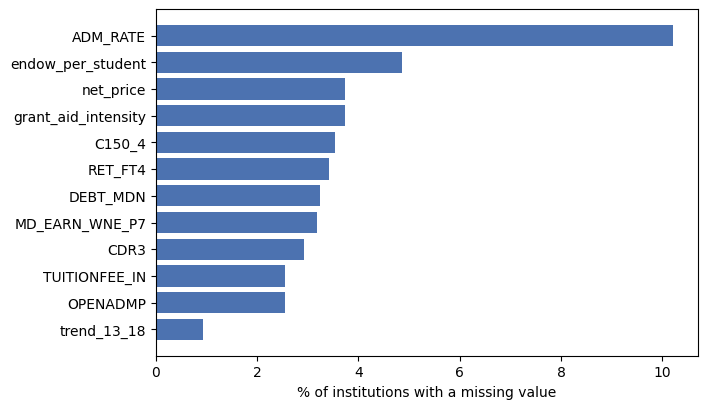

In [ ]:
# the characteristics, grouped as in the metadata table
FEATURE_GROUPS = {
    'location': ['REGION', 'LOCALE'],
    'size': ['log_enroll', 'C18BASIC', 'CONTROL', 'n_campuses'],
    'selectivity': ['ADM_RATE', 'OPENADMP'],
    'price': ['TUITIONFEE_IN', 'net_price', 'grant_aid_intensity'],
    'finances': ['TUITFTE', 'INEXPFTE', 'endow_per_student', 'AVGFACSAL'],
    'student body': ['PCTPELL', 'PCTFLOAN', 'UGDS_BLACK', 'UGDS_HISP', 'UGDS_ASIAN', 'UGDS_NRA', 'PPTUG_EF', 'HBCU'],
    'student outcomes': ['C150_4', 'RET_FT4', 'CDR3', 'MD_EARN_WNE_P7', 'DEBT_MDN'],
    'pre-2018 trend': ['trend_13_18'],
}
all_feats = []
group_of = {}
for g, cols in FEATURE_GROUPS.items():
    for c in cols:
        all_feats.append(c)
        group_of[c] = g
categorical = ['REGION', 'LOCALE', 'C18BASIC', 'CONTROL', 'OPENADMP', 'HBCU']
numeric_feats = [c for c in all_feats if c not in categorical]

miss = pd.DataFrame({
    'overall %': df[all_feats].isna().mean() * 100,
    'public %': df.loc[df['sector'] == 'public', all_feats].isna().mean() * 100,
    'private nonprofit %': df.loc[df['sector'] == 'private nonprofit', all_feats].isna().mean() * 100,
}).sort_values('overall %', ascending=False)
print(miss.round(1).to_string())
print()
to_drop = miss.index[miss['overall %'] > 40].tolist()
print('Characteristics more than 40% missing (to drop):', to_drop if to_drop else '(none)')

# visualization
top = miss.head(12).sort_values('overall %')
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top['overall %'], color='#4C72B0')
ax.set_xlabel('% of institutions with a missing value')
save_fig('fig08_missing_data')
plt.show()

The admission rate had the most missing values (10.2%). All other characteristics were under 5% missing, and 13 had no missing values at all. No characteristic was more than 40% missing, so none was dropped.

The pattern differed by sector. Private nonprofit colleges had more missing values for admission rate (ADM_RATE), endowment per student (endow_per_student), median debt (DEBT_MDN), median earnings (MD_EARN_WNE_P7), and default rate (CDR3). The gap was small for admission rate (10.5% versus 9.5%) and larger for the other four. The Scorecard suppresses debt and earnings when a cohort is too small, and private nonprofit colleges were often small. CDR3 is the three-year cohort default rate. Most missing values came from colleges with no federal borrowers. Only 2 public colleges were missing CDR3. 37 of the 45 private colleges missing  CDR3 had no students with federal loans (PCTFLOAN=0), while several were closed iin 2019 or 2020.

Public colleges had slightly more missing values for completion rate (C150_4), retention rate (RET_FT4), open-admission status (OPENADMP), and in-state tuition (TUITIONFEE_IN). Most of these gaps came from the same 17 public colleges, which did not enroll first-time, first year students. Completion and retention rates are defined only for first-time, full-time students, and open-admission status and in-state tuition were blank for exactly the same institutes, so in this data they also seem tied to first-year admission.

In [ ]:
# do colleges that exited have more missing data?
m_exit = df.loc[df['exit_final'], all_feats].isna().mean() * 100
m_open = df.loc[~df['exit_final'], all_feats].isna().mean() * 100
cmp = pd.DataFrame({'exit %': m_exit, 'not exit %': m_open})
cmp['difference'] = cmp['exit %'] - cmp['not exit %']
print()
print('Largest differences in missing data, exit vs. not exit (percentage points):')
print(cmp.sort_values('difference', ascending=False).head(10).round(1).to_string())


Largest differences in missing data, exit vs. not exit (percentage points):
                     exit %  not exit %  difference
endow_per_student     15.10        4.40       10.70
MD_EARN_WNE_P7        12.30        2.70        9.60
ADM_RATE              16.40        9.90        6.50
CDR3                   8.20        2.70        5.50
RET_FT4                6.80        3.30        3.60
net_price              6.80        3.60        3.30
grant_aid_intensity    6.80        3.60        3.30
OPENADMP               5.50        2.40        3.10
TUITIONFEE_IN          5.50        2.40        3.10
DEBT_MDN               5.50        3.10        2.40


Colleges that exited had more missing data. The largest gaps were in endowment per student, median earnings, admission rate, and dafault rate. This matched Kelchen et al.(2005)'s finding that unusually high rate of missing data among colleges that closed.

**Why is missing**

Some values are missing because the measure doesn't exist for that institute. For example, a college with no federal borrowers has no median debt or default rate. A college with no first-time students has no completion rate or retention rate. The gaps means not applicable, not unknown.

Exit colleges have more missing data. If a value is missing because it came out after college closed, then "missing" carries information from afer 2018. Using it as a predictor would be leakage. The last cell checks whether these gaps cluster among colleges that exited early (2019-2020).

In [ ]:
# Values that do not apply: colleges with no first-time students, and private colleges with no federal borrowers
# (1) completion rate, retention rate, open-admission status, and in-state tuition all missing = no first-time students
first_time_items = ['C150_4', 'RET_FT4', 'OPENADMP', 'TUITIONFEE_IN']
no_first_time = df[first_time_items].isna().all(axis=1)
health = df['C18BASIC'].isin([25, 26])      # Carnegie special focus: medical schools and centers (25), other health professions (26)
college_type = health.map({True: 'health-focused', False: 'other'}).rename('type')
print('Colleges missing all four first-time-student items:', int(no_first_time.sum()))
print(pd.crosstab(df.loc[no_first_time, 'sector'], college_type[no_first_time], margins=True).to_string())
print()
print('Colleges in this group that are not health-focused:')
print(df.loc[no_first_time & ~health, ['INSTNM', 'sector', 'C18BASIC', 'T2018']].to_string(index=False))

# (2) private nonprofit colleges: missing debt, default rate, and earnings
priv = df[df['sector'] == 'private nonprofit']
print()
print('Private nonprofit colleges with a missing value:')
for f in ['DEBT_MDN', 'CDR3', 'MD_EARN_WNE_P7']:
    m = priv[priv[f].isna()]
    print(' ', f, '| missing:', len(m),
          '| no federal borrowers (PCTFLOAN = 0):', int((m['PCTFLOAN'] == 0).sum()),
          '| fewer than 1,000 undergraduates:', int((m['T2018'] < 1000).sum()))

Colleges missing all four first-time-student items: 39
type               health-focused  other  All
sector                                       
private nonprofit              16      6   22
public                         14      3   17
All                            30      9   39

Colleges in this group that are not health-focused:
                                    INSTNM            sector  C18BASIC    T2018
                   Athens State University            public     22.00 2,732.00
                    Golden Gate University private nonprofit     18.00   404.00
            Antioch University-Los Angeles private nonprofit     19.00   338.00
                             Walsh College private nonprofit     29.00   782.00
CUNY Graduate School and University Center            public     15.00 2,105.00
                       Beth Medrash Govoha private nonprofit     24.00 2,680.00
           United States Sports University private nonprofit     32.00   266.00
                      

In [ ]:
# Timing: missing values among exit colleges, by the year the exit became effective
exit_df = df[df['exit_final']].copy()
exit_df['exit_year'] = exit_df['exit_effective_year'].astype(int)
timing = exit_df[['endow_per_student', 'MD_EARN_WNE_P7', 'CDR3']].isna().groupby(exit_df['exit_year']).sum()
timing.insert(0, 'exits', exit_df['exit_year'].value_counts())
timing.loc['all'] = timing.sum()
print('Exit colleges with a missing value, by the year the exit became effective:')
print(timing.to_string())

Exit colleges with a missing value, by the year the exit became effective:
           exits  endow_per_student  MD_EARN_WNE_P7  CDR3
exit_year                                                
2017           1                  0               1     0
2019          11                  2               3     4
2020          13                  3               4     1
2021           6                  1               0     0
2022          11                  0               0     0
2023          15                  3               0     0
2024          16                  2               1     1
all           73                 11               9     6


Most of the gaps had a clear reason. 39 colleges (17 public and 22 private nonprofit) were missing all four first-time student items. 30 of them were medical or health-focused institutions, including 14 of the 17 public ones. Most of the others were upper-divisio or graduate-focused. These institutes enroll few or no first-time, full-timn students, and completion and retention rates are measured only for that group. Open-adminision status and in-state tution were also blank for exactly the same colleges, suggesting them are tied to first-year admission as well. For these colleges, the values are not applicable rather than unknown.

Among private nonprofit colleges, the missing values were mostly due to measures that did not apply or were suppressed. Most colleges without a median debt or a default rate had no students with federal loans. Missing earnings were concentrated among small colleges (43 of 46 had fewer than 1,000 undergraduates), and the Scorecard suppresses earnings for small cohorts.

Some of the extra missing data among exit colleges may be caused by the exit itself. Only 25 of the 73 exits happened by 2020, but they included 8 of the 9 exit colleges missing earnings and 5 of the 6 missing a default rate. These values probably came out after the colleges exited. Missing endowment values occurred in most exit years.

The analysis dropped no characteristic. Notebook 03 will fill the gaps inside each cross-validation training fold, with the median (numeric) or the most common value (categorical).

## Step 9. Distributions of the characteristics

The histograms showed 12 numeric characteristics, which covered every group of characteristics except size and location, because step 7 already showed size, and step 1 showed location.
*   Selectivity: admission rate (ADM_RATE)
*   Price: net price (net_price) and grant aid intensity (grant_aid_intensity)
*   Finances: net tuition revenue per student (TUITFTE), instructional spending per student (INEXPFTE), and endowment per student (endow_per_student)
*   Student body: Pell share (PCTPELL) and Hispanic share (UGDS_HISP)
*   Student outcomes: completion rate (C150_4), retention rate (RET_FT4), and median earnings (MD_EARN_WNE_P7)
*   Pre-2018 trend: trend_13_18

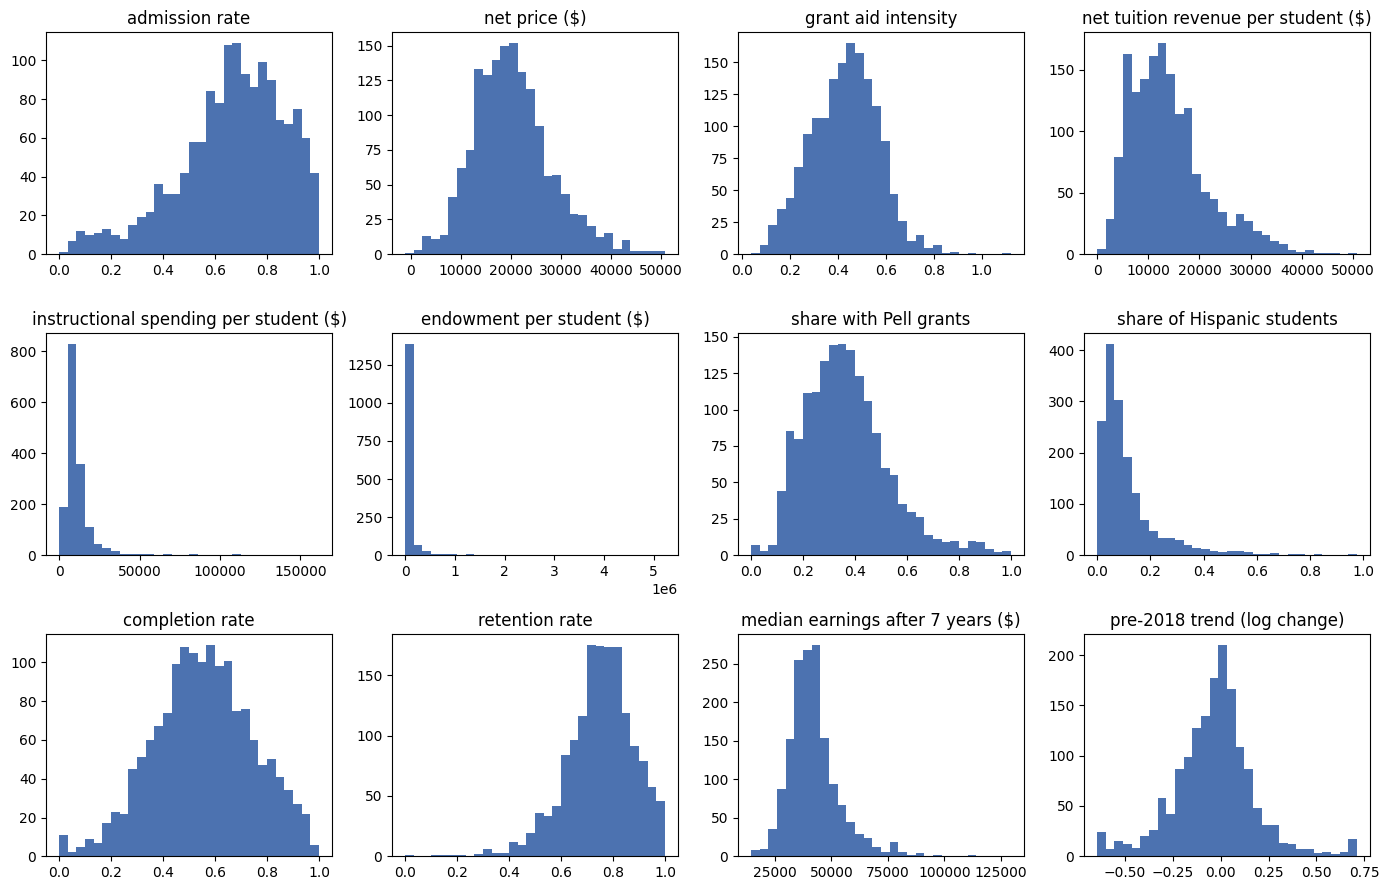

In [ ]:
nice_names = {
    'log_enroll': 'log of enrollment',
    'n_campuses': 'number of campuses',
    'ADM_RATE': 'admission rate',
    'TUITIONFEE_IN': 'in-state tuition and fees ($)',
    'net_price': 'net price ($)',
    'grant_aid_intensity': 'grant aid intensity',
    'TUITFTE': 'net tuition revenue per student ($)',
    'INEXPFTE': 'instructional spending per student ($)',
    'endow_per_student': 'endowment per student ($)',
    'AVGFACSAL': 'average faculty salary ($ per month)',
    'PCTPELL': 'share with Pell grants',
    'PCTFLOAN': 'share with federal loans',
    'UGDS_BLACK': 'share of Black students',
    'UGDS_HISP': 'share of Hispanic students',
    'UGDS_ASIAN': 'share of Asian students',
    'UGDS_NRA': 'share of nonresident students',
    'PPTUG_EF': 'share of part-time students',
    'C150_4': 'completion rate',
    'RET_FT4': 'retention rate',
    'CDR3': 'default rate (3-year)',
    'MD_EARN_WNE_P7': 'median earnings after 7 years ($)',
    'DEBT_MDN': 'median debt ($)',
    'trend_13_18': 'pre-2018 trend (log change)',
}

dist_feats = ['ADM_RATE', 'net_price', 'grant_aid_intensity', 'TUITFTE', 'INEXPFTE', 'endow_per_student',
              'PCTPELL', 'UGDS_HISP', 'C150_4', 'RET_FT4', 'MD_EARN_WNE_P7', 'trend_13_18']
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, f in zip(axes.ravel(), dist_feats):
    ax.hist(df[f].dropna(), bins=30, color='#4C72B0')
    ax.set_title(nice_names[f])
fig.tight_layout()
save_fig('fig09_distributions')
plt.show()

In [ ]:
# skewness of every numeric characteristic
skew_table = pd.DataFrame({'characteristic': [nice_names[f] for f in numeric_feats],
                           'skewness': df[numeric_feats].skew().values}, index=numeric_feats)
print('Skewness of the numeric characteristics:')
print(skew_table.sort_values('skewness').round(2).to_string())

Skewness of the numeric characteristics:
                                             characteristic  skewness
RET_FT4                                      retention rate     -0.79
ADM_RATE                                     admission rate     -0.74
PCTFLOAN                           share with federal loans     -0.67
C150_4                                      completion rate     -0.13
log_enroll                                log of enrollment      0.05
grant_aid_intensity                     grant aid intensity      0.10
trend_13_18                     pre-2018 trend (log change)      0.14
DEBT_MDN                                    median debt ($)      0.16
TUITIONFEE_IN                 in-state tuition and fees ($)      0.46
net_price                                     net price ($)      0.58
PCTPELL                              share with Pell grants      0.81
AVGFACSAL              average faculty salary ($ per month)      0.97
TUITFTE                 net tuition revenue per s

Grant aid intensity, net price, completion rate, and the pre-2018 trend were close to symmetric. Admission rate and retention rate were skewed to the left. Tuition revenue, instructional spending, endowment, median earnings, Pell share, and hispanic share were skewed to the right. Endowment was the most extreme: most had small values, but a few reached about 5 million per student.


The skewness table covered all 23 numeric characteristics. The strongest right skew was number of campuses (15.0), because most institute has exactly one campus, and a few have many.

## Step 10. Characteristics by label

The boxes compared the three labels (10% tolerance) on the 12 characteristics.Differences between the boxes might be early signals. (These are descriptive comparisons, not causal effects.)

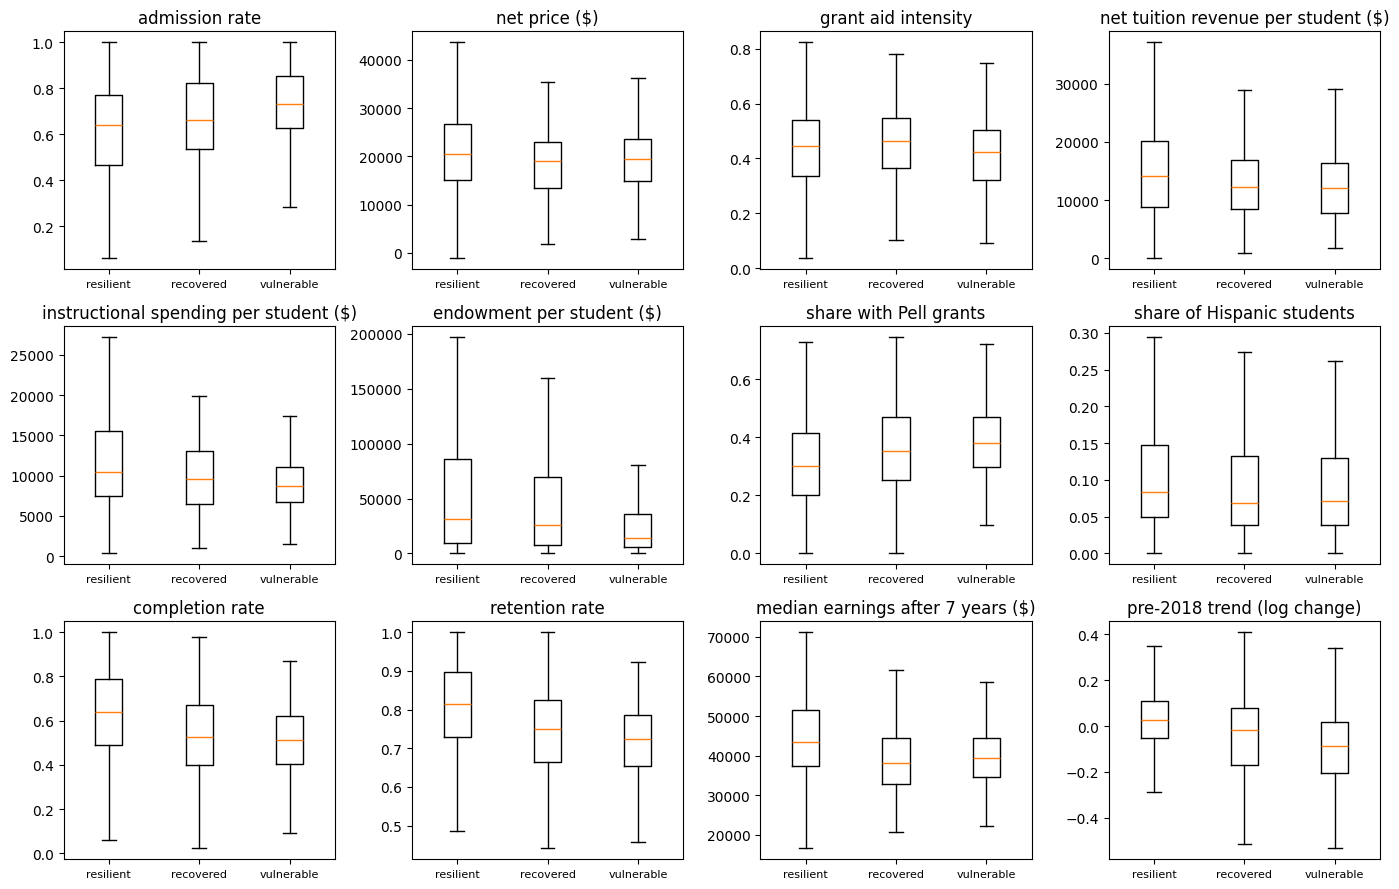

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, f in zip(axes.ravel(), dist_feats):
    data = []
    for lab in label_order:
        data.append(df.loc[df['label_10'] == lab, f].dropna())
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(label_order) + 1))
    ax.set_xticklabels(['resilient', 'recovered', 'vulnerable'], fontsize=8)
    ax.set_title(nice_names[f])
fig.tight_layout()
save_fig('fig10_characteristics_by_label')
plt.show()

Resilient and vulnerable colleges differed most on student outcomes (retention rate, completion rate, and median earnings), wealth (endowment per student and instructional spending per student), and the pre-2018 trend. Resilient colleges had higher retention and completion rates. They had more than twice the endowment per student. They also spent more on instruction. They were growing before 2018, while vulnerable colleges were already shrinking. Vulnerable colleges were less selective and had more students with Pell grants. Net price, grant aid intensity, and the share of Hispanic students looked about the same in all groups. All boxes overlapped, so no single characteristic separated the groups. These were descriptions, not causal effects.

## Step 11. Vulnerable vs. resilient

For each numeric characteristic, this step divides the difference between the mean of vulnerable colleges and the mean of resilient colleges (10% tolerance) by their typical spread, the pooled standard deviation. A negative value means vulnerable colleges have a lower mean than resilient colleges. A positive value means a higher mean. A value of 0.5 means the two means are half a standard deviation apart. This is a quick screen, not a test.

In [ ]:
# Define the function
def std_diff(a, b):
    # standardized difference between the means of two groups
    a = a.dropna()
    b = b.dropna()
    pooled = np.sqrt((a.var() + b.var()) / 2)
    return (a.mean() - b.mean()) / pooled

In [ ]:
# Vulnerable minus resilient, for each numeric characteristic
vul = df[df['label_10'] == 'vulnerable']
res = df[df['label_10'] == 'resilient']
rows = []
for f in numeric_feats:
    rows.append({'characteristic': nice_names[f], 'group': group_of[f], 'standardized difference': std_diff(vul[f], res[f])})
sd = pd.DataFrame(rows)
sd['abs'] = sd['standardized difference'].abs()
sd = sd.sort_values('abs', ascending=False)
print(sd[['characteristic', 'group', 'standardized difference']].round(2).to_string(index=False))

                        characteristic            group  standardized difference
                        retention rate student outcomes                    -0.70
              share with federal loans     student body                     0.66
  average faculty salary ($ per month)         finances                    -0.64
           pre-2018 trend (log change)   pre-2018 trend                    -0.62
                        admission rate      selectivity                     0.61
                       completion rate student outcomes                    -0.61
                 default rate (3-year) student outcomes                     0.52
                share with Pell grants     student body                     0.45
               share of Asian students     student body                    -0.41
     median earnings after 7 years ($) student outcomes                    -0.41
             endowment per student ($)         finances                    -0.39
instructional spending per s

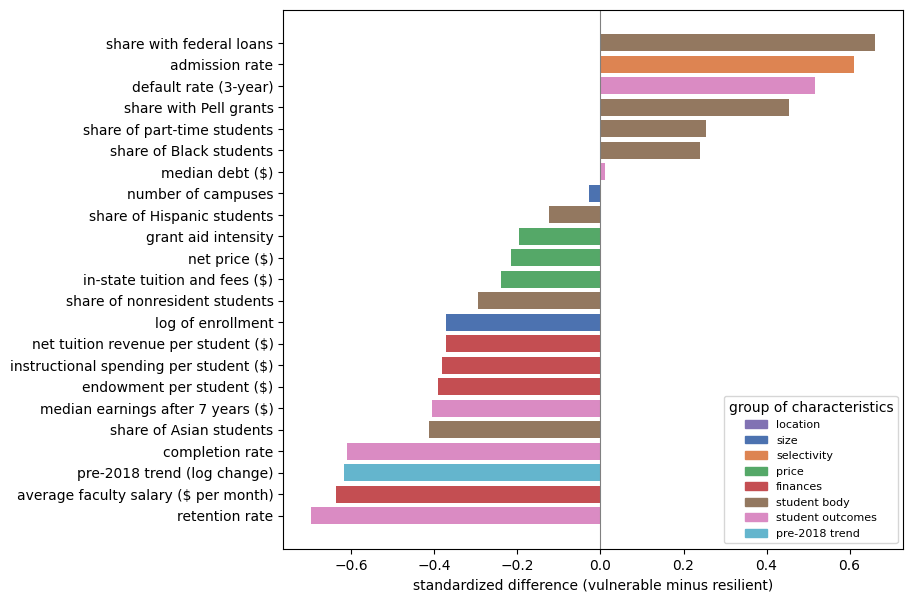

In [ ]:
# visulization
group_colors = {'location': '#8172B3', 'size': '#4C72B0', 'selectivity': '#DD8452', 'price': '#55A868',
                'finances': '#C44E52', 'student body': '#937860', 'student outcomes': '#DA8BC3', 'pre-2018 trend': '#64B5CD'}
plot_sd = sd.sort_values('standardized difference')
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(plot_sd['characteristic'], plot_sd['standardized difference'], color=[group_colors[g] for g in plot_sd['group']])
ax.axvline(0, color='grey', linewidth=0.8)
ax.set_xlabel('standardized difference (vulnerable minus resilient)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in group_colors.items()], title='group of characteristics', loc='lower right', fontsize=8)
save_fig('fig11_standardized_differences')
plt.show()

The largest differences were moderate, about 0.6 to 0.7 standard deviations. Vulnerable colleges had lower retention rates (−0.70), lower faculty salaries (−0.64), a weaker pre-2018 trend (−0.62), and lower completion rates (−0.61). They also had a larger share of students with federal loans (0.66) and higher admission rates (0.61). Default rate (0.52) and the share of students with Pell grants (0.45) came next.

Student outcomes, finances, and the student body each had several large differences. Price showed only small differences.

Two of the six largest differences, federal loans and faculty salary, were not among the 12 characteristics in Steps 9 and 10. This finding does not affect the models, because the models use all the characteristics, not only the 12 in the plots.

## Step 12 Overlap among the characteristics

Characteristics that move together make single coefficients unstable, which is why the models rank groups of characteristics. This step shows the correlations and the variance inflation factor (VIF). The VIF of a characteristic says how well the other characteristics predict it: 1 means no overlap, and above about 5 to 10 means heavy overlap. Missing values are filled with the median for this screening only.

In [ ]:
# Define the function
def vif_table(frame):
    # variance inflation factor of every column
    X = frame.fillna(frame.median())              # fill gaps with the median (screening only)
    X = (X - X.mean()) / X.std()                  # standardize
    out = {}
    for col in X.columns:
        y = X[col].values
        others = X.drop(columns=col).values
        A = np.column_stack([np.ones(len(X)), others])          # the other columns plus an intercept
        coef = np.linalg.lstsq(A, y, rcond=None)[0]
        resid = y - A @ coef
        r2 = 1 - resid.var() / y.var()                          # how well the others predict this column
        out[col] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

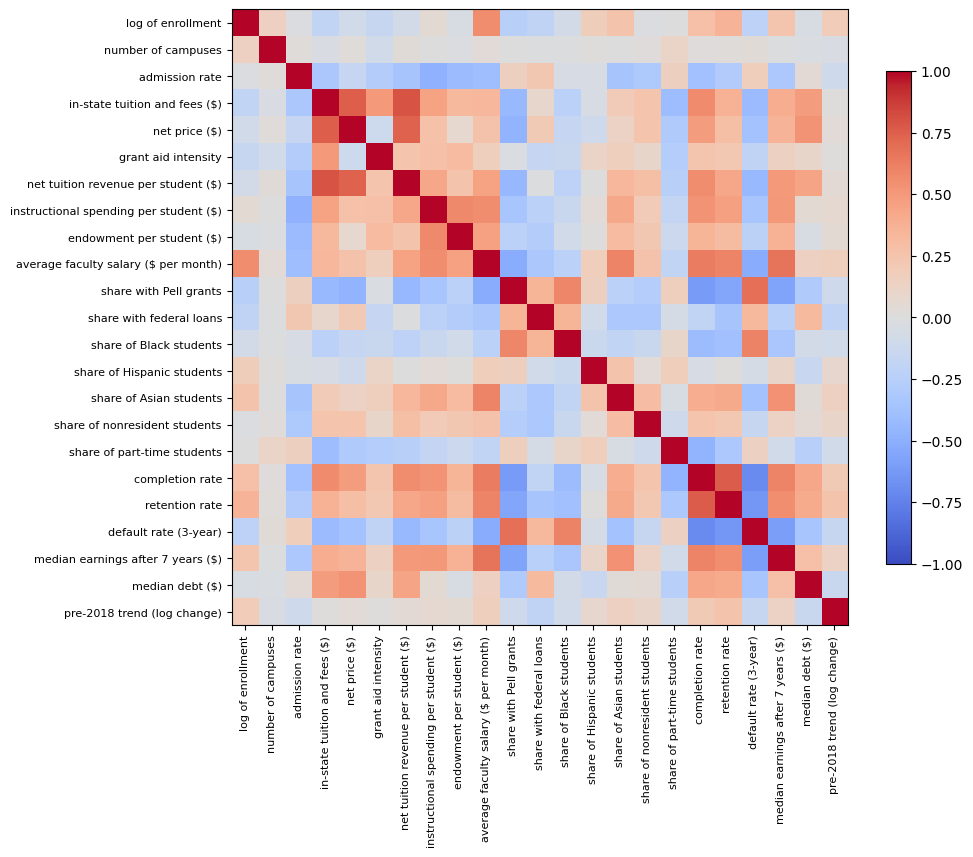

In [ ]:
corr = df[numeric_feats].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_feats)))
ax.set_yticks(range(len(numeric_feats)))
ax.set_xticklabels([nice_names[f] for f in numeric_feats], rotation=90, fontsize=8)
ax.set_yticklabels([nice_names[f] for f in numeric_feats], fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
save_fig('fig12_correlation_heatmap')
plt.show()

In [ ]:
top_pairs = []
for i in range(len(numeric_feats)):
    for j in range(i + 1, len(numeric_feats)):
        top_pairs.append({'characteristic 1': nice_names[numeric_feats[i]],
                          'characteristic 2': nice_names[numeric_feats[j]],
                          'correlation': corr.iloc[i, j]})
top_pairs = pd.DataFrame(top_pairs)
top_pairs['abs'] = top_pairs['correlation'].abs()
print('The 10 strongest pairs of characteristics:')
print(top_pairs.sort_values('abs', ascending=False).head(10).drop(columns='abs').round(2).to_string(index=False))

The 10 strongest pairs of characteristics:
                    characteristic 1                    characteristic 2  correlation
       in-state tuition and fees ($) net tuition revenue per student ($)         0.79
                     completion rate                      retention rate         0.76
       in-state tuition and fees ($)                       net price ($)         0.76
                       net price ($) net tuition revenue per student ($)         0.74
                     completion rate               default rate (3-year)        -0.70
              share with Pell grants               default rate (3-year)         0.68
average faculty salary ($ per month)   median earnings after 7 years ($)         0.67
                      retention rate               default rate (3-year)        -0.64
average faculty salary ($ per month)                     completion rate         0.63
              share with Pell grants                     completion rate        -0.61


No pair of characteristics had a correlation of 0.8 or more. The strongest pairs were in-state tuition with net tuition revenue (0.79), completion with retention (0.76), in-state tuition with net price (0.76), and net price with net tuition revenue (0.74).

In [ ]:
# pairs with a correlation of 0.8 or more (in absolute value)
pairs = []
for i in range(len(numeric_feats)):
    for j in range(i + 1, len(numeric_feats)):
        r = corr.iloc[i, j]
        if abs(r) >= 0.8:
            pairs.append((nice_names[numeric_feats[i]], numeric_feats[j], round(r, 2)))
print('Pairs with |correlation| of at least 0.8:')
for p in pairs:
    print('  ', p)
if not pairs:
    print('   none')

vif = vif_table(df[numeric_feats])
print()
print('Variance inflation factors (highest first):')
print(vif.rename(index=nice_names).round(1).head(10).to_string())
print('Characteristics with a VIF above 5:', [nice_names[f] for f in vif.index[vif > 5]])

Pairs with |correlation| of at least 0.8:
   none

Variance inflation factors (highest first):
in-state tuition and fees ($)          14.00
net price ($)                           9.30
grant aid intensity                     5.30
average faculty salary ($ per month)    4.90
completion rate                         4.10
net tuition revenue per student ($)     3.60
share with Pell grants                  3.50
retention rate                          3.10
default rate (3-year)                   2.90
median earnings after 7 years ($)       2.60
Characteristics with a VIF above 5: ['in-state tuition and fees ($)', 'net price ($)', 'grant aid intensity']


Three characteristics had a VIF above 5, all in the price group: in-state tuition and fees (14.0), net price (9.3), and grant aid intensity (5.3). They overlap by construction. Grant aid intensity comes from net price and the cost of attendance, and tuition is a large part of that cost. As a result, they stayed together in the price group. The analysis reported importance for groups of characteristics, not single coefficients.

## Step 13. Public vs. private nonprofit

Median value of each numeric characteristic by sector, and the standardized difference between the sectors. This shows whether the two sectors look different enough to need separate models (RQ-b). Negative values mean private nonprofit colleges had higher values.

In [ ]:
by_sector = df.groupby('sector')[numeric_feats].median().T
pub = df[df['sector'] == 'public']
pnp = df[df['sector'] == 'private nonprofit']
by_sector['standardized difference (public minus private)'] = [std_diff(pub[f], pnp[f]) for f in by_sector.index]
by_sector['abs'] = by_sector['standardized difference (public minus private)'].abs()
by_sector = by_sector.rename(index=nice_names)
print(by_sector.sort_values('abs', ascending=False).drop(columns='abs').round(2).to_string())

sector                                  private nonprofit    public  standardized difference (public minus private)
in-state tuition and fees ($)                   31,436.00  8,748.00                                           -2.39
log of enrollment                                    7.25      8.92                                            1.60
net price ($)                                   22,440.00 14,435.00                                           -1.42
net tuition revenue per student ($)             15,225.00  7,148.50                                           -1.37
grant aid intensity                                  0.48      0.34                                           -0.88
median debt ($)                                 18,126.50 14,500.00                                           -0.74
average faculty salary ($ per month)             7,062.00  8,441.00                                            0.49
share with federal loans                             0.62      0.49     

The two sectors differed most on price and size. Private nonprofit colleges had much higher median in-state tuition. They also had higher median net prices, net tuition revenue per student, and grant aid intensity. Private colleges had more students with federal loans and higher median debt.

Public colleges were much larger. They paid higher median faculty salaries, had more part-time students, and admitted a larger share of applicants.

Most student outcomes were similar. Retention, median earnings, and default rate were all within 0.2. Only completion was moderately higher at private colleges. Pell share, instructional spending, and the pre-2018 trend were also similar.

Endowment per student was about four times higher at private nonprofit colleges, but its standardized difference was small (-0.32) because a few very rich colleges made the spread very large.

In a model with both sectors, price and size could partly stand for sector. Separate models for each sector (RQ2) can show whether price and size still matter within a sector.

## Step 14. Exit colleges

Within private nonprofit colleges, the standardized difference in each characteristic between the 63 exit colleges （48 closures and 15 mergers) and the others 1,019 private nonprofit colleges on several groups at once. Public exits are mergers (10), so they are left out of this comparison. This is a description, not a model: with 63 exit events, only a few characteristics can be used in a model.

Private nonprofit institutions: exit = 63 | not exit = 1019
                        characteristic            group  median, exit  median, not exit  standardized difference
                        retention rate student outcomes          0.64              0.77                    -0.96
                     log of enrollment             size          6.27              7.28                    -0.95
                share with Pell grants     student body          0.49              0.33                     0.82
              share with federal loans     student body          0.72              0.61                     0.81
  average faculty salary ($ per month)         finances      5,917.50          7,220.50                    -0.74
                       completion rate student outcomes          0.44              0.59                    -0.71
           pre-2018 trend (log change)   pre-2018 trend         -0.20             -0.02                    -0.59
                 default rate (3-yea

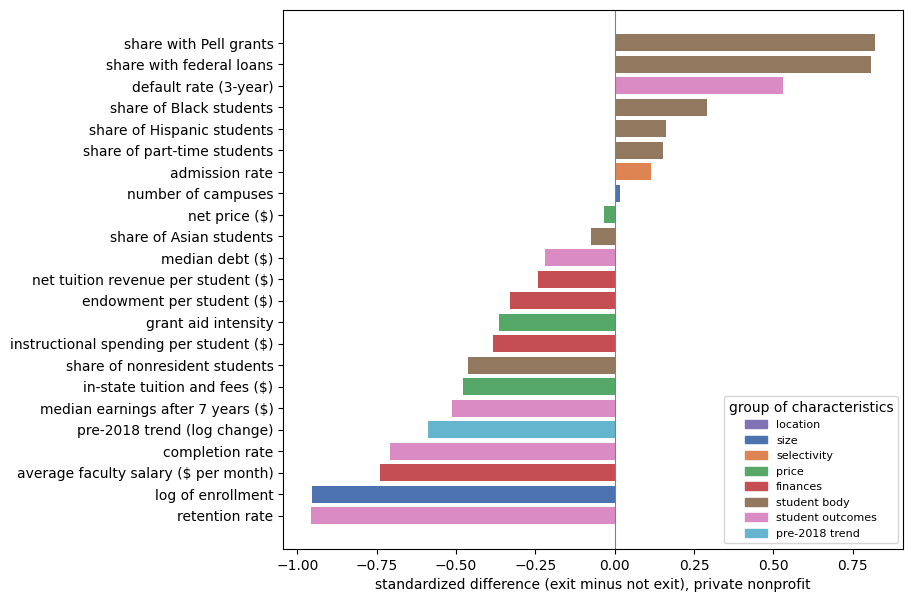

In [ ]:
ex = pnp[pnp['exit_final']]
op = pnp[~pnp['exit_final']]
print('Private nonprofit institutions: exit =', len(ex), '| not exit =', len(op))

rows = []
for f in numeric_feats:
    rows.append({'characteristic': nice_names[f], 'group': group_of[f],
                 'median, exit': ex[f].median(), 'median, not exit': op[f].median(),
                 'standardized difference': std_diff(ex[f], op[f])})
ed = pd.DataFrame(rows)
ed['abs'] = ed['standardized difference'].abs()
ed = ed.sort_values('abs', ascending=False)
print(ed.drop(columns='abs').head(12).round(2).to_string(index=False))

plot_ed = ed.sort_values('standardized difference')
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(plot_ed['characteristic'], plot_ed['standardized difference'], color=[group_colors[g] for g in plot_ed['group']])
ax.axvline(0, color='grey', linewidth=0.8)
ax.set_xlabel('standardized difference (exit minus not exit), private nonprofit')
ax.legend(handles=[Patch(color=c, label=g) for g, c in group_colors.items()], title='group of characteristics', loc='lower right', fontsize=8)
save_fig('fig13_exit_vs_open')
plt.show()

Exit colleges were much smaller. They also had weaker student outcomes: lower retention (−0.96), lower completion (−0.71), higher default rates (0.53), and lower earnings (−0.51). They served more low-income students, with more students receiving Pell grants (0.82) and federal loans (0.81). They had fewer resources, with lower faculty salaries and lower instructional spending. They were already shrinking before 2018 (-0.59).

High price did not mark exits. Exit colleges had lower in-state tuition (-0.48), and their net price was about the same as that of other colleges Admissioin rate also showed little difference.

Compared with step 11, size mattered much more for exits, and admission rate mattered much less.

The exit colleges therefore shared a distinct profile: small, shrinking, with fewer resources, more low-income students who borrowed, and weaker outcomes. Several of these characteristics overlap, such as Pell grants, federal loans, and default rate. With only 63 exits, the exit model could use only a few characteristics, ideally one from each of these groups.

In [ ]:
# Choosing the five characteristics for the exit model
pn = df[df['sector'] == 'private nonprofit']
is_exit = pn['exit_final'].astype(bool)

# show the top 2 characteristics in the top 5 groups
diffs = pd.DataFrame([{'characteristic': f, 'group': group_of[f],
                       'standardized difference': std_diff(pn.loc[is_exit, f], pn.loc[~is_exit, f]),
                       'missing among exits': int(pn.loc[is_exit, f].isna().sum())}   # Rule 2
                      for f in numeric_feats])
diffs['abs'] = diffs['standardized difference'].abs()
best = diffs.sort_values('abs', ascending=False).groupby('group').head(2)   # top two in each group, to show near ties
print(best.sort_values(['abs'], ascending=False).drop(columns='abs').round(2).to_string(index=False))

     characteristic            group  standardized difference  missing among exits
            RET_FT4 student outcomes                    -0.96                    5
         log_enroll             size                    -0.95                    0
            PCTPELL     student body                     0.82                    0
           PCTFLOAN     student body                     0.81                    0
          AVGFACSAL         finances                    -0.74                    1
             C150_4 student outcomes                    -0.71                    4
        trend_13_18   pre-2018 trend                    -0.59                    1
      TUITIONFEE_IN            price                    -0.48                    4
           INEXPFTE         finances                    -0.38                    0
grant_aid_intensity            price                    -0.36                    5
           ADM_RATE      selectivity                     0.12                   10
    

In [ ]:
# Tie-break in the student body group: overlap with the other four chosen characteristics
others = ['log_enroll', 'RET_FT4', 'AVGFACSAL', 'trend_13_18']
print()
print('Correlation with the other four characteristics (private nonprofit):')
print(pn[['PCTPELL', 'PCTFLOAN'] + others].corr().loc[['PCTPELL', 'PCTFLOAN'], others].round(2).to_string())

EXIT_FEATURES = ['log_enroll', 'RET_FT4', 'PCTFLOAN', 'AVGFACSAL', 'trend_13_18']
print()
print('Characteristics for the exit model:', EXIT_FEATURES)


Correlation with the other four characteristics (private nonprofit):
          log_enroll  RET_FT4  AVGFACSAL  trend_13_18
PCTPELL        -0.38    -0.57      -0.60        -0.10
PCTFLOAN       -0.03    -0.38      -0.28        -0.17

Characteristics for the exit model: ['log_enroll', 'RET_FT4', 'PCTFLOAN', 'AVGFACSAL', 'trend_13_18']


The model uses one characteristic from each of the five groups with the largest differences between exits and open colleges, choosing the one with the largest difference and few missing values among exits. In the student body group, the Pell share and the federal loan share were nearly tied (0.82 vs. 0.81). The model uses the federal loan share because it overlaps less with the other four characteristics.